# Paywall price test

**The question.** A free app has a paid tier behind a paywall. Should it charge **EUR 4.99** or **EUR 6.99** a month?

**The method.** Users who reach the paywall are split at random into two groups. Group A sees EUR 4.99, group B sees EUR 6.99. Each user is followed for 12 months and the groups are compared.

**The data.** Simulated by `data/simulate.py`. No real users.

The notebook has six parts, then a list of limitations:

1. **Design**: decide what to measure and how many users are needed, before looking at any result.
2. **Analysis**: compare the two groups.
3. **Traps**: three ways to read the same test wrongly.
4. **Decision**: what to do, and what would change it.
5. **Open data**: the same method applied to two public datasets.
6. **A Bayesian reading**: the same test seen as probabilities and expected losses.

In [1]:
import math
from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
import numpy as np
import pandas as pd
from scipy.stats import norm

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
FIGURES = ROOT / "figures"

# Chart style: the fonts are optional, the notebook runs without them.
for font in (ROOT / "fonts").glob("*.ttf"):
    fm.fontManager.addfont(str(font))
plt.style.use(ROOT / "notebooks" / "style.mplstyle")

BLUE, INK, MUTED, ORANGE = "#3C62B3", "#13294B", "#4B5563", "#CC7318"

---
## Part 1. Design

Everything in this part is decided **before** the results are opened. A metric or a stopping point chosen after seeing the numbers can make almost any test "work". Fixing the rules first is what makes the result believable.

### 1.1 What is measured

| Metric | Role | Definition |
|---|---|---|
| **12-month revenue per user** | Primary: the decision rests on it | Revenue in the first 12 months / all users who saw the paywall |
| Conversion to paid | Secondary | Users who paid at least once / all users who saw the paywall |
| Trial start rate | Secondary | Users who started a trial / all users who saw the paywall |
| Months paid per payer | Guardrail | Average number of months paid in the first 12, among payers |

"Per user" always means per user who **saw the paywall**, whether they paid or not. Dividing by payers only would hide the users lost to the higher price.

### 1.2 The hypothesis

- **Null hypothesis:** the price makes no difference to the metric. Any gap between the groups is chance.
- **Alternative:** the two prices give different results.

The test is two-sided: neither price is assumed to be better in advance.

### 1.3 Three numbers to fix in advance

| Term | Value | Plain meaning |
|---|---|---|
| **Significance level** (alpha) | 5% | If the two prices are in fact equal, there is a 5% risk of wrongly declaring a difference: a false alarm. |
| **Power** | 80% | If the prices really differ by the amount below, the test detects it with an 80% chance. |
| **Smallest effect worth detecting** | conversion falls from 5.0% to 4.6% | A fall of 8% in relative terms. A smaller fall would not change the decision, so the users needed to see it are not worth their cost. |

The 5.0% baseline is an assumption about the current paywall. In a real product it comes from past data.

5% and 80% are conventions, not laws. They are the usual starting point in product experiments.

In [2]:
ALPHA = 0.05       # significance level, two-sided
POWER = 0.80
P_A = 0.050        # assumed conversion to paid at EUR 4.99
P_B = 0.046        # smallest change worth detecting at EUR 6.99


def users_per_group(p1, p2, alpha=ALPHA, power=POWER):
    """Users needed in each group to tell two conversion rates apart (two-sided z-test)."""
    z_alpha = norm.ppf(1 - alpha / 2)   # 1.96 for alpha = 5%
    z_power = norm.ppf(power)           # 0.84 for power = 80%
    variance = p1 * (1 - p1) + p2 * (1 - p2)
    return math.ceil((z_alpha + z_power) ** 2 * variance / (p1 - p2) ** 2)


N = users_per_group(P_A, P_B)
print(f"Users needed per group: {N:,}")
print(f"Users needed in total:  {2 * N:,}")

Users needed per group: 44,829
Users needed in total:  89,658


### 1.4 Reading the sample size

The formula has three ingredients:

- **The level of certainty required** (the 1.96 and 0.84 above). Stricter levels need more users.
- **How noisy the metric is** (the variance). A conversion rate near 5% is a rare event, so each user carries little information.
- **How small the effect is** (the gap between 5.0% and 4.6%). It enters **squared**, which is what makes small effects expensive.

The chart shows the last point. Each step to a smaller effect multiplies the users needed.

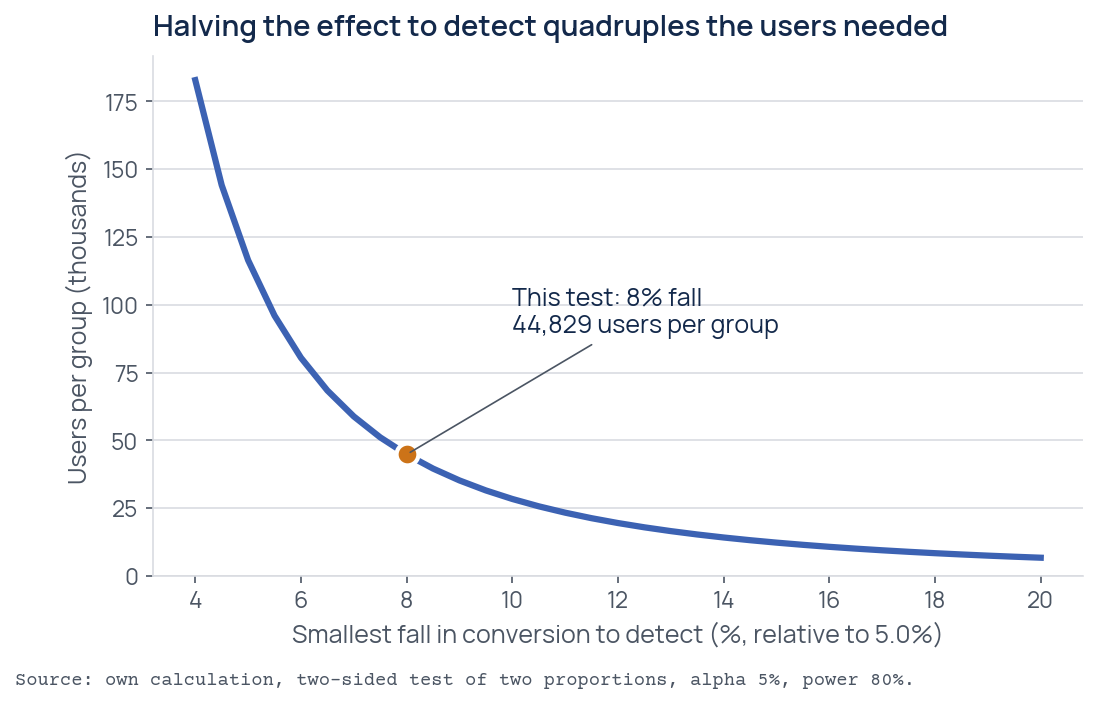

In [3]:
drops = np.arange(0.04, 0.2001, 0.005)                 # relative fall in conversion
needed = np.array([users_per_group(P_A, P_A * (1 - d)) for d in drops])

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(100 * drops, needed / 1000, color=BLUE, linewidth=3)
ax.scatter([8], [N / 1000], s=110, color=ORANGE, edgecolor="white", linewidth=2, zorder=3)
ax.annotate(f"This test: 8% fall\n{N:,} users per group", xy=(8, N / 1000),
            xytext=(10, N / 1000 + 45), color=INK,
            arrowprops=dict(arrowstyle="-", color=MUTED, linewidth=0.8))
ax.set_title("Halving the effect to detect quadruples the users needed")
ax.set_xlabel("Smallest fall in conversion to detect (%, relative to 5.0%)")
ax.set_ylabel("Users per group (thousands)")
ax.set_xticks(range(4, 21, 2))
ax.set_ylim(0, None)
fig.text(0.01, -0.05, "Source: own calculation, two-sided test of two proportions, alpha 5%, power 80%.",
         family="monospace", fontsize=9, color=MUTED)
fig.savefig(FIGURES / "01_sample_size.png", dpi=200, bbox_inches="tight")
plt.show()

### 1.5 What this test can and cannot see

With the sample size fixed, the power depends on how large the true effect is. The table gives the chance that the test detects a fall of each size.

In [4]:
def power_at(p1, p2, n, alpha=ALPHA):
    """Chance that a two-sided z-test with n users per group detects the gap p1 - p2."""
    se = math.sqrt((p1 * (1 - p1) + p2 * (1 - p2)) / n)
    return norm.cdf(abs(p1 - p2) / se - norm.ppf(1 - alpha / 2))


rows = []
for drop in (0.04, 0.06, 0.08, 0.10, 0.12):
    p_b = P_A * (1 - drop)
    rows.append({"True fall in conversion": f"{drop:.0%}",
                 "Conversion at 6.99": f"{p_b:.2%}",
                 "Chance the test detects it": f"{power_at(P_A, p_b, N):.0%}"})
pd.DataFrame(rows).set_index("True fall in conversion")

,Conversion at 6.99,Chance the test detects it
True fall in conversion,,
4%,4.80%,28%
6%,4.70%,55%
8%,4.60%,80%
10%,4.50%,94%
12%,4.40%,99%


A fall of 8% is detected 80% of the time, as designed. A fall of 4% would be missed about seven times in ten. This is by design: a 4% fall is too small to change the decision.

### 1.6 How long the test runs

In [5]:
TEST_DAYS = 56
print(f"Users per day needed to finish in {TEST_DAYS} days: {2 * N / TEST_DAYS:,.0f}")

Users per day needed to finish in 56 days: 1,601


The test runs for **8 full weeks**. Whole weeks matter because behaviour differs between weekdays and weekends, and a test that stops mid-week over-weights some days. Eight weeks also leaves time for any first-days reaction to the new price to fade.

Each user is then followed for **12 months**, because the primary metric is 12-month revenue.

### 1.7 The rules, written down before the results

1. **One analysis, at the end.** The result is read once, after all users have been enrolled. No stopping early because it "looks good".
2. **Primary metric: 12-month revenue per user.** Conversion alone does not decide.
3. **Unit: the user.** Each user is in one group only and is counted once.
4. **Significance level 5%, two-sided.**
5. **Decision rule.** Keep EUR 6.99 if revenue per user is higher and the difference is distinguishable from chance. Otherwise keep EUR 4.99, the current price.

### 1.8 How this is done in practice

This exercise starts from two given prices. The points below describe common practice as reported in practitioner guides. They are context, not findings of this notebook.

- **Candidate prices are chosen before the test.** A team can look at what comparable products charge and at how its own funnel compares with similar apps, then pick the prices worth testing. Here EUR 4.99 and EUR 6.99 are simply assumed.
- **Pricing is tested before visual changes.** A new layout or a countdown timer is easier to judge once the price is settled, and each test changes one thing so its effect can be read.
- **Duration and target numbers are fixed before launch.** A minimum running time and the number of subscriptions needed are set in advance. This is what sections 1.3 to 1.7 do.
- **Real paywalls offer several plans.** Weekly, monthly and annual plans sit side by side, and the price of one changes how the others look. This exercise tests a single monthly price.
- **Prices can differ by country.** Each market can be tested on its own. This exercise has one market.

### 1.9 Limitations of the design

- **Sized on conversion, decided on revenue.** The sample size is planned on conversion, because conversion can be planned with a simple formula before any data exists. The decision rests on revenue, which is noisier: it depends on who pays *and* on how long they stay. Part 2 measures how precise the revenue comparison actually is.
- **The baseline is assumed.** The 5.0% conversion is an assumption. If the true baseline were lower, the same test would have less power.
- **Conventions, not laws.** The 5% significance level and 80% power are the usual choices. A team that fears a wrong price change more than a missed opportunity would choose stricter values.
- **Twelve months is a long wait.** The primary metric needs a year of follow-up. A team can decide earlier on a forecast of retention, which adds its own uncertainty. This notebook observes the full 12 months because the data is simulated.

---
## Part 2. Analysis

The rules of part 1 apply: the data is read **once**, at the end of the test, and the decision rests on 12-month revenue per user.

### 2.1 Load and check the data

Before any comparison, check that the file is what the design says: the right number of users, two groups of equal size, no missing values, no user counted twice.

In [6]:
users = pd.read_csv(ROOT / "data" / "users.csv", parse_dates=["exposure_date"])

print(f"Rows:                 {len(users):,}")
print(f"Users per group:      {users.groupby('group').size().to_dict()}")
print(f"Missing values:       {int(users.isna().sum().sum())}")
print(f"Duplicate user ids:   {int(users['user_id'].duplicated().sum())}")
print(f"First and last day:   {users['exposure_date'].min().date()} to {users['exposure_date'].max().date()}")
users.head()

Rows:                 89,658
Users per group:      {'A': 44829, 'B': 44829}
Missing values:       0
Duplicate user ids:   0
First and last day:   2025-01-06 to 2025-03-02


,user_id,group,price_eur,exposure_date,started_trial,paid,months_paid,revenue_12m
0,u_000001,B,6.99,2025-02-07,0,0,0,0.0
1,u_000002,A,4.99,2025-01-29,0,0,0,0.0
2,u_000003,A,4.99,2025-02-19,0,0,0,0.0
3,u_000004,A,4.99,2025-02-13,0,0,0,0.0
4,u_000005,B,6.99,2025-02-22,0,0,0,0.0


The two groups have the same size, as the design requires. In a real test this check matters: if a 50/50 split comes out 52/48, something in the assignment is broken and the comparison cannot be trusted.

### 2.2 The funnel in each group

One line per group, from seeing the paywall to revenue.

In [7]:
A = users[users["group"] == "A"]
B = users[users["group"] == "B"]
N_GROUP = len(A)


def funnel(g):
    payers = g["paid"].sum()
    return {
        "Price (EUR / month)": g["price_eur"].iloc[0],
        "Users who saw the paywall": len(g),
        "Started a trial": int(g["started_trial"].sum()),
        "Paid at least once": int(payers),
        "Conversion to paid (%)": 100 * g["paid"].mean(),
        "Months paid per payer": g["months_paid"].sum() / payers,
        "12-month revenue (EUR)": g["revenue_12m"].sum(),
        "Revenue per user (EUR)": g["revenue_12m"].mean(),
    }


table = pd.DataFrame({"Group A": funnel(A), "Group B": funnel(B)})
table["Change (%)"] = 100 * (table["Group B"] / table["Group A"] - 1)
table.loc["Users who saw the paywall", "Change (%)"] = np.nan
table.round(2)

,Group A,Group B,Change (%)
Price (EUR / month),4.99,6.99,40.08
Users who saw the paywall,44829.00,44829.00,NaN
Started a trial,5263.00,5032.00,-4.39
Paid at least once,2258.00,2076.00,-8.06
Conversion to paid (%),5.04,4.63,-8.06
Months paid per payer,7.25,6.02,-16.93
12-month revenue (EUR),81686.30,87395.97,6.99
Revenue per user (EUR),1.82,1.95,6.99


Group B has fewer payers and each stays for fewer months, but each pays 40% more per month. Revenue per user ends up higher in B. The next two sections ask the same question of each gap: **could it be chance?**

### 2.3 Conversion: is the fall real?

The tool is a **two-proportion z-test**. In plain words: if the price made no difference, the two conversion rates would still differ a little by chance. The test measures how large the observed gap is compared with that chance variation.

- The **p-value** is the probability of seeing a gap at least this large if the price made no difference. Below 5%, the gap is called statistically significant.
- The **95% confidence interval** is the range of gaps compatible with the data.

In [8]:
def compare_proportions(x_a, x_b):
    """Two-sided z-test for two proportions, with a 95% confidence interval for the gap."""
    p_a, p_b, n_a, n_b = x_a.mean(), x_b.mean(), len(x_a), len(x_b)
    pooled = (x_a.sum() + x_b.sum()) / (n_a + n_b)
    z = (p_b - p_a) / math.sqrt(pooled * (1 - pooled) * (1 / n_a + 1 / n_b))
    se = math.sqrt(p_a * (1 - p_a) / n_a + p_b * (1 - p_b) / n_b)
    gap = p_b - p_a
    return gap, (gap - 1.96 * se, gap + 1.96 * se), 2 * norm.sf(abs(z))


gap, ci, p_conv = compare_proportions(A["paid"], B["paid"])
print(f"Conversion A: {A['paid'].mean():.2%}    Conversion B: {B['paid'].mean():.2%}")
print(f"Gap (B - A):  {100 * gap:+.2f} percentage points")
print(f"95% interval: {100 * ci[0]:+.2f} to {100 * ci[1]:+.2f} percentage points")
print(f"p-value:      {p_conv:.4f}")

Conversion A: 5.04%    Conversion B: 4.63%
Gap (B - A):  -0.41 percentage points
95% interval: -0.69 to -0.13 percentage points
p-value:      0.0046


The whole interval is below zero and the p-value is 0.005. **The higher price lowers conversion.** This is the expected cost of charging more.

### 2.4 Revenue per user: is the gain real?

Revenue per user is harder to compare than conversion. About 95% of users pay nothing, and the rest pay between one and twelve months, so the values are widely spread. Two methods are used, and they should agree:

- **Welch's t-test** compares the two averages and allows the groups to have different spreads.
- **The bootstrap** makes no assumption about the shape of the data. It redraws the users of each group at random, with replacement, 5,000 times, and looks at how much the result moves.

In [9]:
from scipy.stats import ttest_ind

rev_a, rev_b = A["revenue_12m"].to_numpy(), B["revenue_12m"].to_numpy()

# Welch's t-test
diff = rev_b.mean() - rev_a.mean()
se_diff = math.sqrt(rev_a.var(ddof=1) / len(rev_a) + rev_b.var(ddof=1) / len(rev_b))
p_rev = ttest_ind(rev_b, rev_a, equal_var=False).pvalue

print(f"Revenue per user A: EUR {rev_a.mean():.3f}    B: EUR {rev_b.mean():.3f}")
print(f"Gap (B - A):        EUR {diff:+.3f}  ({diff / rev_a.mean():+.1%})")
print(f"95% interval:       EUR {diff - 1.96 * se_diff:+.3f} to {diff + 1.96 * se_diff:+.3f}")
print(f"p-value (Welch):    {p_rev:.3f}")

Revenue per user A: EUR 1.822    B: EUR 1.950
Gap (B - A):        EUR +0.127  (+7.0%)
95% interval:       EUR -0.003 to +0.258
p-value (Welch):    0.055


In [10]:
def bootstrap_means(values, rng, repeats=5000, block=100):
    """Average of `values` in each of `repeats` random redraws with replacement."""
    n = len(values)
    out = np.empty(repeats)
    for start in range(0, repeats, block):
        picks = rng.integers(0, n, size=(block, n))
        out[start:start + block] = values[picks].mean(axis=1)
    return out


rng = np.random.default_rng(1)
boot_rev_a, boot_rev_b = bootstrap_means(rev_a, rng), bootstrap_means(rev_b, rng)
boot_conv_a = bootstrap_means(A["paid"].to_numpy(float), rng)
boot_conv_b = bootstrap_means(B["paid"].to_numpy(float), rng)

rev_lift = rev_b.mean() / rev_a.mean() - 1
conv_lift = B["paid"].mean() / A["paid"].mean() - 1
rev_ci = np.percentile(boot_rev_b / boot_rev_a - 1, [2.5, 97.5])
conv_ci = np.percentile(boot_conv_b / boot_conv_a - 1, [2.5, 97.5])
gap_ci = np.percentile(boot_rev_b - boot_rev_a, [2.5, 97.5])

print(f"Bootstrap 95% interval for the revenue gap: EUR {gap_ci[0]:+.3f} to {gap_ci[1]:+.3f}")
print(f"Revenue per user, relative change:  {rev_lift:+.1%}  (95% interval {rev_ci[0]:+.1%} to {rev_ci[1]:+.1%})")
print(f"Conversion, relative change:        {conv_lift:+.1%}  (95% interval {conv_ci[0]:+.1%} to {conv_ci[1]:+.1%})")
print(f"Share of redraws where B earns no more than A: {(boot_rev_b <= boot_rev_a).mean():.1%}")

Bootstrap 95% interval for the revenue gap: EUR -0.005 to +0.255
Revenue per user, relative change:  +7.0%  (95% interval -0.3% to +14.4%)
Conversion, relative change:        -8.1%  (95% interval -13.3% to -2.5%)
Share of redraws where B earns no more than A: 2.8%


The two methods agree. Revenue per user is about 7% higher in group B, but the interval runs from slightly below zero to about +14%, and the p-value is just above 5%. **The revenue gain is not statistically significant at the level fixed in part 1.**

The chart puts the two results side by side.

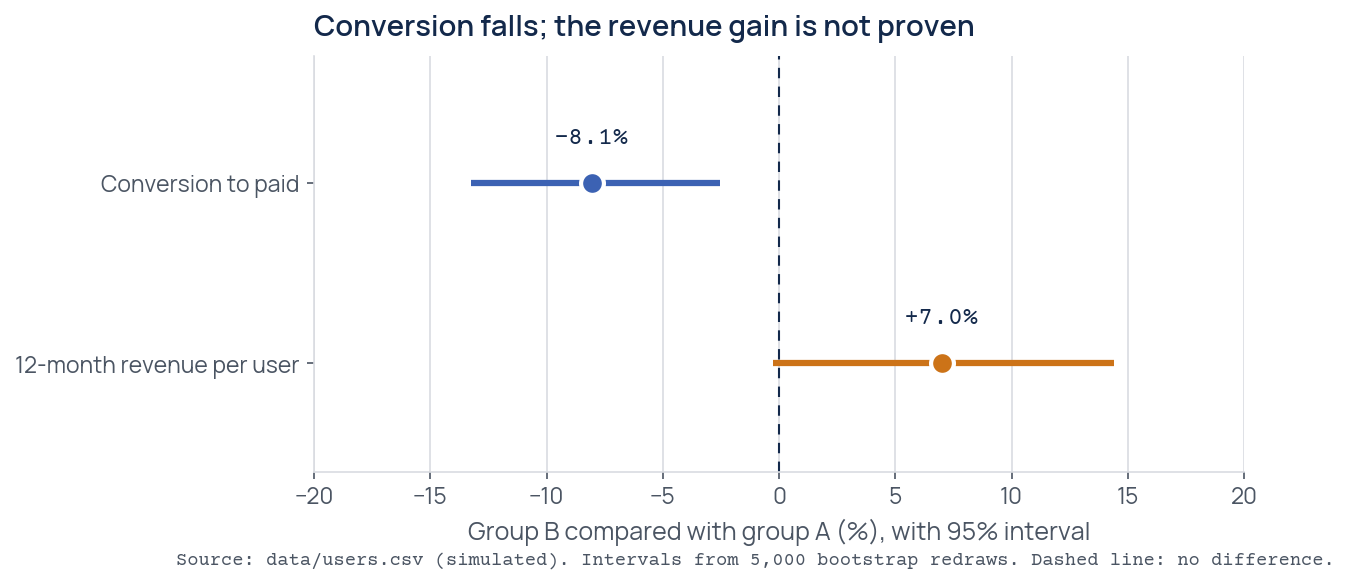

In [11]:
fig, ax = plt.subplots(figsize=(8, 3.6))
rows = [("12-month revenue per user", rev_lift, rev_ci, ORANGE), ("Conversion to paid", conv_lift, conv_ci, BLUE)]
for y, (label, value, interval, colour) in enumerate(rows):
    ax.plot([100 * interval[0], 100 * interval[1]], [y, y], color=colour, linewidth=3, solid_capstyle="butt")
    ax.scatter([100 * value], [y], s=120, color=colour, edgecolor="white", linewidth=2, zorder=3)
    ax.text(100 * value, y + 0.22, f"{value:+.1%}", ha="center", color=INK, family="monospace")
ax.axvline(0, color=INK, linewidth=1, linestyle=(0, (5, 4)))
ax.set_yticks([0, 1], [r[0] for r in rows])
ax.set_ylim(-0.6, 1.7)
ax.set_xlim(-20, 20)
ax.grid(axis="y", visible=False)
ax.grid(axis="x", visible=True)
ax.set_xlabel("Group B compared with group A (%), with 95% interval")
ax.set_title("Conversion falls; the revenue gain is not proven")
fig.text(0.01, -0.06, "Source: data/users.csv (simulated). Intervals from 5,000 bootstrap redraws. Dashed line: no difference.",
         family="monospace", fontsize=9, color=MUTED)
fig.savefig(FIGURES / "02_conversion_vs_revenue.png", dpi=200, bbox_inches="tight")
plt.show()

### 2.5 Where the revenue change comes from

Revenue per user is the product of three terms: **conversion × price × months paid per payer**. The table shows how each term moves from A to B. The three changes multiply to the change in revenue.

In [12]:
terms = pd.DataFrame(
    {
        "Group A": [A["paid"].mean(), A["price_eur"].iloc[0], A["months_paid"].sum() / A["paid"].sum()],
        "Group B": [B["paid"].mean(), B["price_eur"].iloc[0], B["months_paid"].sum() / B["paid"].sum()],
    },
    index=["Conversion to paid", "Price (EUR / month)", "Months paid per payer"],
)
terms.loc["Revenue per user (EUR) = product"] = terms.prod()
terms["Change (%)"] = 100 * (terms["Group B"] / terms["Group A"] - 1)
terms.round(3)

,Group A,Group B,Change (%)
Conversion to paid,0.050,0.046,-8.060
Price (EUR / month),4.990,6.990,40.080
Months paid per payer,7.250,6.023,-16.927
Revenue per user (EUR) = product,1.822,1.950,6.990


The price adds 40%. Lower conversion takes away about 8% and shorter subscriptions about 17%. What is left is the gain of about 7%.

### 2.6 Was this dataset typical? Repeating the experiment 300 times

A real test is run once, so nobody can tell whether their result was a typical draw or an unusual one. With simulated data this can be checked. The cell below runs the same experiment 300 more times, each with a different random seed, and records the revenue gain of group B each time.

In [13]:
import sys

sys.path.insert(0, str(ROOT / "data"))
import simulate

repeat_lift, repeat_significant = [], []
for seed in range(300):
    run = simulate.simulate(seed)
    a = run.loc[run["group"] == "A", "revenue_12m"].to_numpy()
    b = run.loc[run["group"] == "B", "revenue_12m"].to_numpy()
    repeat_lift.append(b.mean() / a.mean() - 1)
    repeat_significant.append(ttest_ind(b, a, equal_var=False).pvalue < ALPHA and b.mean() > a.mean())
repeat_lift = np.array(repeat_lift)

print(f"Average revenue gain over 300 repeats:  {repeat_lift.mean():+.1%}")
print(f"Middle 90% of the repeats:              {np.percentile(repeat_lift, 5):+.1%} to {np.percentile(repeat_lift, 95):+.1%}")
print(f"Lowest and highest repeat:              {repeat_lift.min():+.1%} and {repeat_lift.max():+.1%}")
print(f"Repeats with a significant gain for B:  {np.mean(repeat_significant):.0%}")
print(f"This dataset:                           {rev_lift:+.1%}")

Average revenue gain over 300 repeats:  +17.6%
Middle 90% of the repeats:              +11.5% to +24.6%
Lowest and highest repeat:              +9.1% and +29.4%
Repeats with a significant gain for B:  100%
This dataset:                           +7.0%


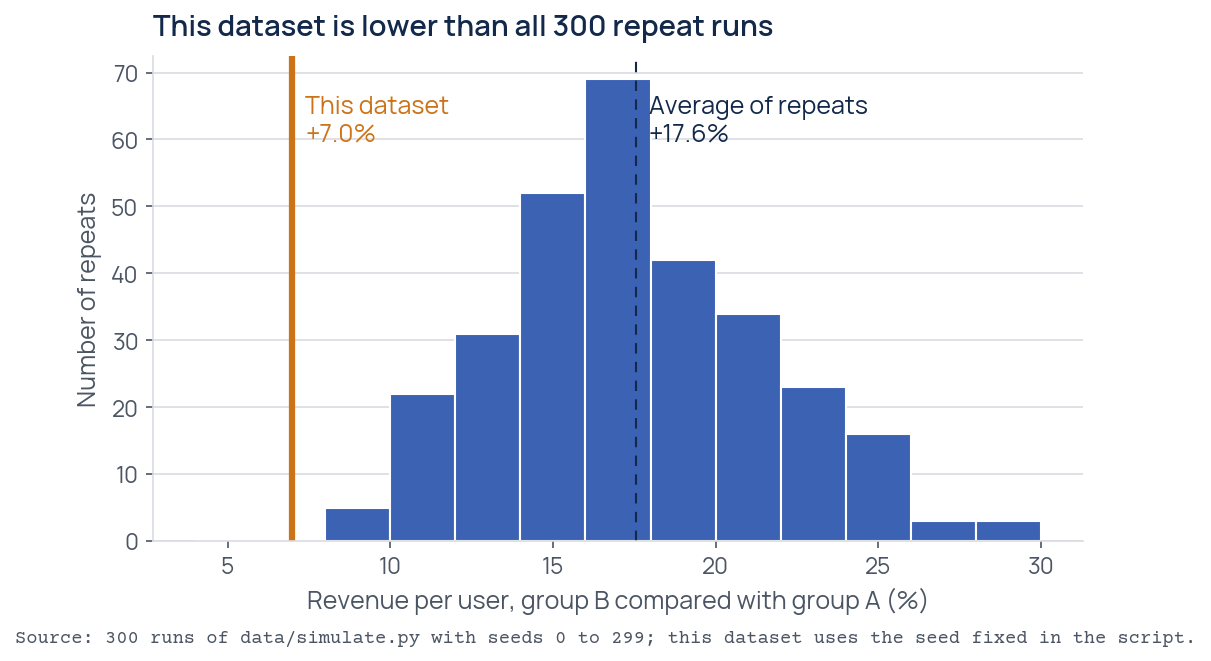

In [14]:
fig, ax = plt.subplots(figsize=(8, 4.2))
ax.hist(100 * repeat_lift, bins=np.arange(4, 32, 2), color=BLUE, edgecolor="white", linewidth=1)
ax.axvline(100 * rev_lift, color=ORANGE, linewidth=3)
ax.text(100 * rev_lift + 0.4, ax.get_ylim()[1] * 0.92, f"This dataset\n{rev_lift:+.1%}", color=ORANGE, va="top")
ax.axvline(100 * repeat_lift.mean(), color=INK, linewidth=1, linestyle=(0, (5, 4)))
ax.text(100 * repeat_lift.mean() + 0.4, ax.get_ylim()[1] * 0.92, f"Average of repeats\n{repeat_lift.mean():+.1%}", color=INK, va="top")
ax.set_xlabel("Revenue per user, group B compared with group A (%)")
ax.set_ylabel("Number of repeats")
ax.set_title("This dataset is lower than all 300 repeat runs")
fig.text(0.01, -0.05, "Source: 300 runs of data/simulate.py with seeds 0 to 299; this dataset uses the seed fixed in the script.",
         family="monospace", fontsize=9, color=MUTED)
fig.savefig(FIGURES / "03_repeats.png", dpi=200, bbox_inches="tight")
plt.show()

The simulation is built so that EUR 6.99 earns about 17% to 18% more per user. The test finds a significant gain in all 300 repeats. **The dataset analysed here is an unusually unlucky draw**: by chance, the payers of group A stayed longer than expected and those of group B shorter.

The dataset was not replaced. Choosing a seed because its result looks better would be a form of the cherry-picking that part 3 warns about. It also shows something a single real test cannot: a correctly designed test can still land on a misleading result, and nothing inside that one test reveals it.

### 2.7 What the analysis says

| Question | Answer from this dataset |
|---|---|
| Does EUR 6.99 lower conversion? | Yes: from 5.04% to 4.63%, statistically significant. |
| Does EUR 6.99 raise 12-month revenue per user? | Probably: +7.0%, but the interval includes zero (p = 0.055). |
| By the rule of part 1? | The gain is not distinguishable from chance at the 5% level, so the rule does not allow switching to EUR 6.99 on this test alone. |
| What do the repeats add? | The design detects the gain in 300 runs out of 300. This run is the exception, and only the simulation reveals it. |

The decision itself is taken in the last part, after the traps.

### 2.8 Limitations of the analysis

- **One draw.** The analysis rests on one simulated dataset, and section 2.6 shows it is an unusual one. Its numbers should not be read as the typical outcome of this design.
- **Borderline result.** A p-value of 0.055 and one of 0.045 carry almost the same evidence. The 5% threshold is a convention fixed in advance, not a line between true and false.
- **Revenue is noisier than conversion.** The test was sized for conversion. It can detect revenue gains of roughly 10% or more with good reliability, and the observed 7% falls below that.
- **The repeats are not available in real life.** Section 2.6 is possible only because the data is simulated. A real team sees one run.
- **No segments.** All users are treated alike. Real users differ by country, device and acquisition channel, and the best price may differ between them.

---
## Part 3. Three traps

Parts 1 and 2 followed the rules. This part breaks them on purpose, one at a time, to show what each rule protects against. Every trap uses the same data or the same design.

### 3.1 Trap 1: peeking

**The mistake.** The result is checked every few days and the test is stopped as soon as it shows a significant difference.

**Why it is a mistake.** The 5% significance level means: if the prices are equal, one look at the end gives a false alarm 5% of the time. Each extra look is another chance for noise to cross the line. Stop at the first crossing and the false alarms add up.

**The demonstration.** The cell simulates 20,000 tests in which the two groups have the **same** conversion rate (5.0%), so any "significant" result is a false alarm by construction. Each test is read once, twice, 5, 10 or 20 times at equal intervals.

In [15]:
rng = np.random.default_rng(2)
SIMS, BLOCKS = 20_000, 20
block = N_GROUP // BLOCKS                      # users added to each group between two looks

# Cumulative payers in two groups with the SAME true conversion rate.
payers_a = rng.binomial(block, P_A, size=(SIMS, BLOCKS)).cumsum(axis=1)
payers_b = rng.binomial(block, P_A, size=(SIMS, BLOCKS)).cumsum(axis=1)
n_so_far = block * np.arange(1, BLOCKS + 1)
pooled = (payers_a + payers_b) / (2 * n_so_far)
z = (payers_b - payers_a) / n_so_far / np.sqrt(pooled * (1 - pooled) * 2 / n_so_far)
significant = np.abs(z) > norm.ppf(1 - ALPHA / 2)

false_alarms = {}
for looks in (1, 2, 5, 10, 20):
    when = np.arange(1, looks + 1) * BLOCKS // looks - 1      # equally spaced looks
    false_alarms[looks] = significant[:, when].any(axis=1).mean()

pd.DataFrame({"Chance of a false alarm (%)": {k: round(100 * v, 1) for k, v in false_alarms.items()}}).rename_axis("Number of looks")

,Chance of a false alarm (%)
Number of looks,
1,5.0
2,8.2
5,14.0
10,19.1
20,25.0


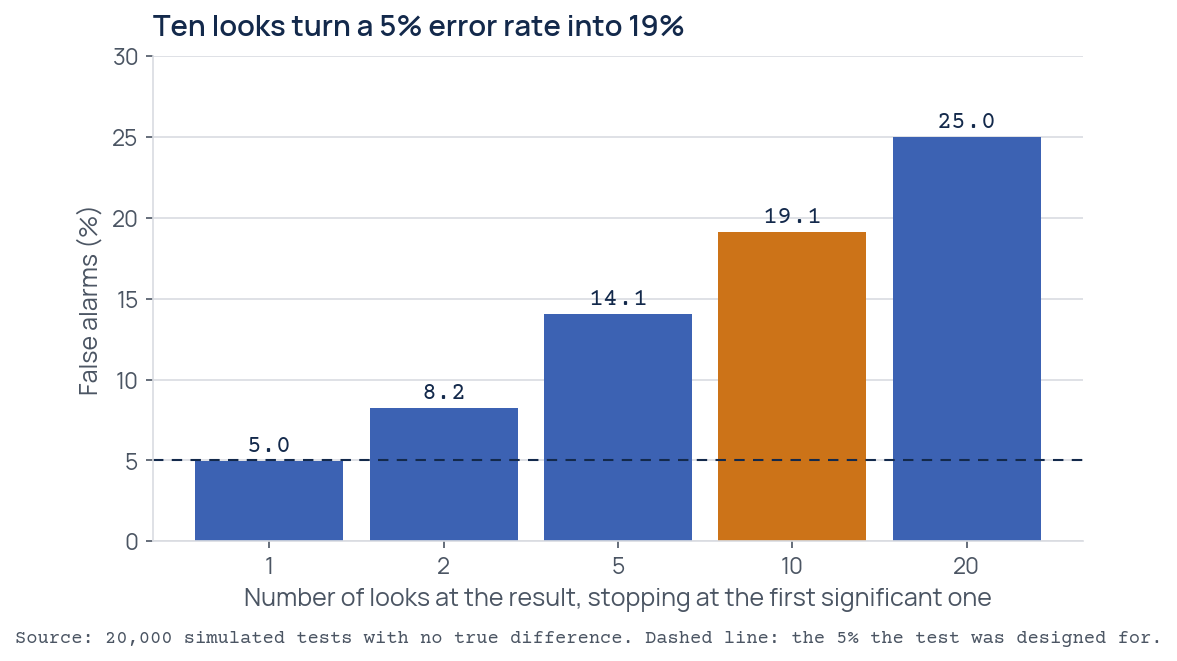

In [16]:
fig, ax = plt.subplots(figsize=(8, 4.2))
labels = [str(k) for k in false_alarms]
values = [100 * v for v in false_alarms.values()]
colours = [ORANGE if k == 10 else BLUE for k in false_alarms]
ax.bar(labels, values, width=0.85, color=colours)
for x, v in enumerate(values):
    ax.text(x, v + 0.6, f"{v:.1f}", ha="center", family="monospace", color=INK)
ax.axhline(100 * ALPHA, color=INK, linewidth=1, linestyle=(0, (5, 4)))
ax.set_ylim(0, 30)
ax.set_xlabel("Number of looks at the result, stopping at the first significant one")
ax.set_ylabel("False alarms (%)")
ax.set_title(f"Ten looks turn a 5% error rate into {100 * false_alarms[10]:.0f}%")
fig.text(0.01, -0.05, "Source: 20,000 simulated tests with no true difference. Dashed line: the 5% the test was designed for.",
         family="monospace", fontsize=9, color=MUTED)
fig.savefig(FIGURES / "04_peeking.png", dpi=200, bbox_inches="tight")
plt.show()

These rates are in line with Armitage, McPherson and Rowe, "Repeated significance tests on accumulating data", Journal of the Royal Statistical Society, Series A, 132(2), 235-244 (1969), which showed that repeated tests on accumulating data inflate the false-alarm rate.

**The same trap in this test's data.** The next cell reads the test at the end of each week, as an impatient team would.

In [17]:
users["day"] = (users["exposure_date"] - users["exposure_date"].min()).dt.days
weekly = []
for week in range(1, 9):
    so_far = users[users["day"] < 7 * week]
    a, b = so_far.loc[so_far["group"] == "A", "paid"], so_far.loc[so_far["group"] == "B", "paid"]
    gap_w, _, p_w = compare_proportions(a, b)
    weekly.append({"After week": week, "Users so far": len(so_far),
                   "Conversion gap (pp)": round(100 * gap_w, 2), "p-value": round(p_w, 3),
                   "Verdict if the test stopped here": "significant" if p_w < ALPHA else "not significant"})
pd.DataFrame(weekly).set_index("After week")

,Users so far,Conversion gap (pp),p-value,Verdict if the test stopped here
After week,,,,
1,11088,-0.21,0.622,not significant
2,22287,-0.24,0.417,not significant
3,33424,-0.51,0.031,significant
4,44686,-0.31,0.122,not significant
5,55856,-0.41,0.023,significant
6,67092,-0.48,0.004,significant
7,78433,-0.43,0.005,significant
8,89658,-0.41,0.005,significant


The verdict changes with the day of reading: not significant after two weeks, significant after three, not significant again after four, then significant. A team that stops at the first "significant" reading reports a result that the next week would have withdrawn.

**The protection.** Decide the sample size first and read the result once, at the end (rule 1 of part 1). If early stopping is needed, use a method built for it, such as a sequential test, which spends the 5% across the planned looks.

### 3.2 Trap 2: the novelty effect

**The mistake.** The test is judged on its first days.

**Why it is a mistake.** Users can react to a change because it is new, not because it is better. The reaction fades. In this simulation, group B gets 25% more trial starts on the first day, and the boost fades within about two weeks.

**The demonstration.** The chart compares the conversion gap between the groups, week by week, with the gap built into the simulation.

In [18]:
users["week"] = users["day"] // 7 + 1
rows = []
for week, chunk in users.groupby("week"):
    a, b = chunk.loc[chunk["group"] == "A", "paid"], chunk.loc[chunk["group"] == "B", "paid"]
    ratio = b.mean() / a.mean()
    se_log = math.sqrt((1 - a.mean()) / a.sum() + (1 - b.mean()) / b.sum())
    rows.append({"week": week, "gap": ratio - 1,
                 "low": ratio * math.exp(-1.96 * se_log) - 1, "high": ratio * math.exp(1.96 * se_log) - 1})
by_week = pd.DataFrame(rows).set_index("week")

# The gap built into the simulation, averaged over the days of each week.
days = np.arange(simulate.TEST_DAYS)
built_in_daily = (simulate.PAID_RATE["B"] / simulate.PAID_RATE["A"]) * (
    1 + simulate.NOVELTY_BOOST * np.exp(-days / simulate.NOVELTY_DECAY_DAYS)) - 1
built_in = built_in_daily.reshape(8, 7).mean(axis=1)

first_week = users[users["week"] == 1]
later = users[users["week"] > 1]
gap_first = first_week.loc[first_week["group"] == "B", "paid"].mean() / first_week.loc[first_week["group"] == "A", "paid"].mean() - 1
gap_later = later.loc[later["group"] == "B", "paid"].mean() / later.loc[later["group"] == "A", "paid"].mean() - 1
print(f"Conversion gap in week 1:        {gap_first:+.1%}   (built into the simulation: {built_in[0]:+.1%})")
print(f"Conversion gap in weeks 2 to 8:  {gap_later:+.1%}   (built into the simulation: {built_in[1:].mean():+.1%})")

Conversion gap in week 1:        -3.9%   (built into the simulation: +5.7%)
Conversion gap in weeks 2 to 8:  -8.7%   (built into the simulation: -7.4%)


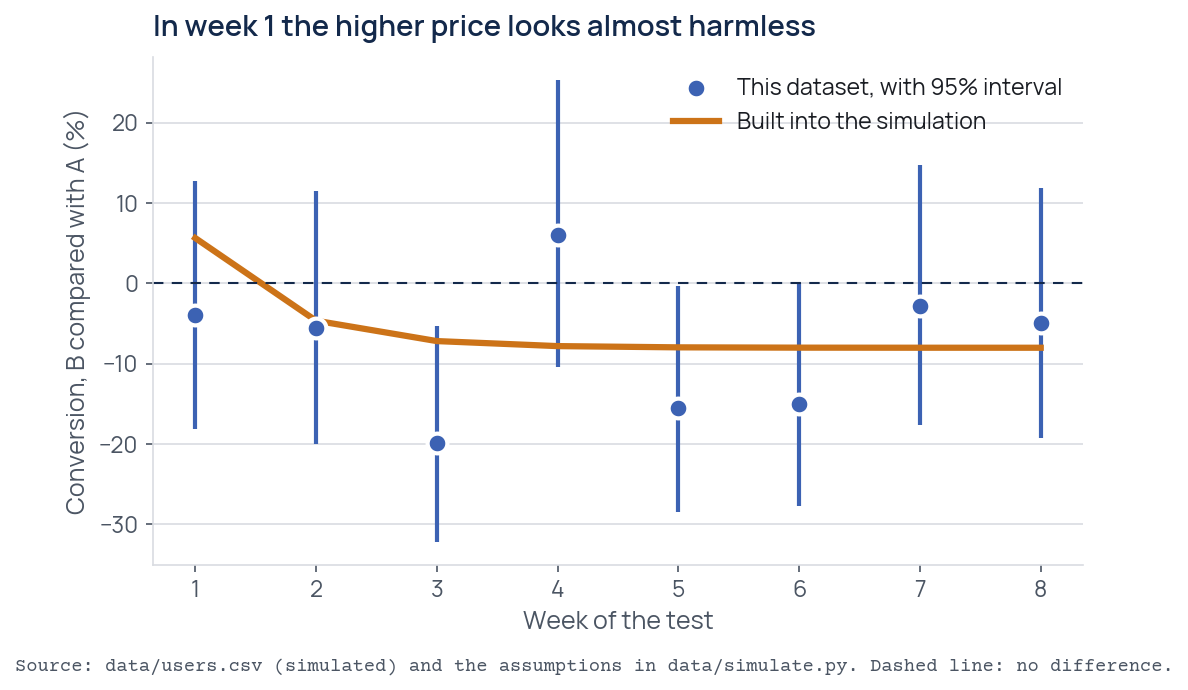

In [19]:
fig, ax = plt.subplots(figsize=(8, 4.4))
weeks = by_week.index.to_numpy()
ax.vlines(weeks, 100 * by_week["low"], 100 * by_week["high"], color=BLUE, linewidth=2)
ax.scatter(weeks, 100 * by_week["gap"], s=90, color=BLUE, edgecolor="white", linewidth=2, zorder=3, label="This dataset, with 95% interval")
ax.plot(weeks, 100 * built_in, color=ORANGE, linewidth=3, label="Built into the simulation")
ax.axhline(0, color=INK, linewidth=1, linestyle=(0, (5, 4)))
ax.set_xticks(weeks)
ax.set_xlabel("Week of the test")
ax.set_ylabel("Conversion, B compared with A (%)")
ax.set_title("In week 1 the higher price looks almost harmless")
ax.legend(frameon=False, loc="upper right")
fig.text(0.01, -0.05, "Source: data/users.csv (simulated) and the assumptions in data/simulate.py. Dashed line: no difference.",
         family="monospace", fontsize=9, color=MUTED)
fig.savefig(FIGURES / "05_novelty.png", dpi=200, bbox_inches="tight")
plt.show()

The orange line is the truth of the simulation: in week 1 the novelty boost more than offsets the price, so group B converts slightly **better** than A, and from week 3 the gap settles near -8%. The blue points are what one dataset shows. Week 1 gives -3.9%, about half the gap of the later weeks (-8.7%), and its interval includes zero.

Two lessons follow. A test stopped after one week would conclude that the higher price barely hurts conversion. Single weeks are also noisy. With about 5,600 users per group per week, the weekly points scatter widely around the line, so one dataset cannot establish the novelty effect. It has to be allowed for in the design.

**The protection.** Run the test long enough for first reactions to fade (8 weeks in part 1), and check whether the first week differs from the rest before trusting the total.

### 3.3 Trap 3: the wrong metric

**The mistake.** The price is judged on a metric that sees only part of the picture.

**The demonstration.** The same two groups, measured three ways.

In [20]:
payers_A, payers_B = A["paid"].sum(), B["paid"].sum()
metrics = pd.DataFrame(
    {
        "Group A": [A["paid"].mean() * 100, A["revenue_12m"].sum() / payers_A, A["revenue_12m"].mean()],
        "Group B": [B["paid"].mean() * 100, B["revenue_12m"].sum() / payers_B, B["revenue_12m"].mean()],
    },
    index=["Conversion to paid (%)", "Revenue per paying user (EUR)", "Revenue per user (EUR)"],
)
metrics["Change (%)"] = 100 * (metrics["Group B"] / metrics["Group A"] - 1)
metrics["What it ignores"] = ["How much each payer pays, and for how long", "The users who no longer pay at all", "Nothing: it combines the other two"]
metrics.round(2)

,Group A,Group B,Change (%),What it ignores
Conversion to paid (%),5.04,4.63,-8.06,"How much each payer pays, and for how long"
Revenue per paying user (EUR),36.18,42.10,16.37,The users who no longer pay at all
Revenue per user (EUR),1.82,1.95,6.99,Nothing: it combines the other two


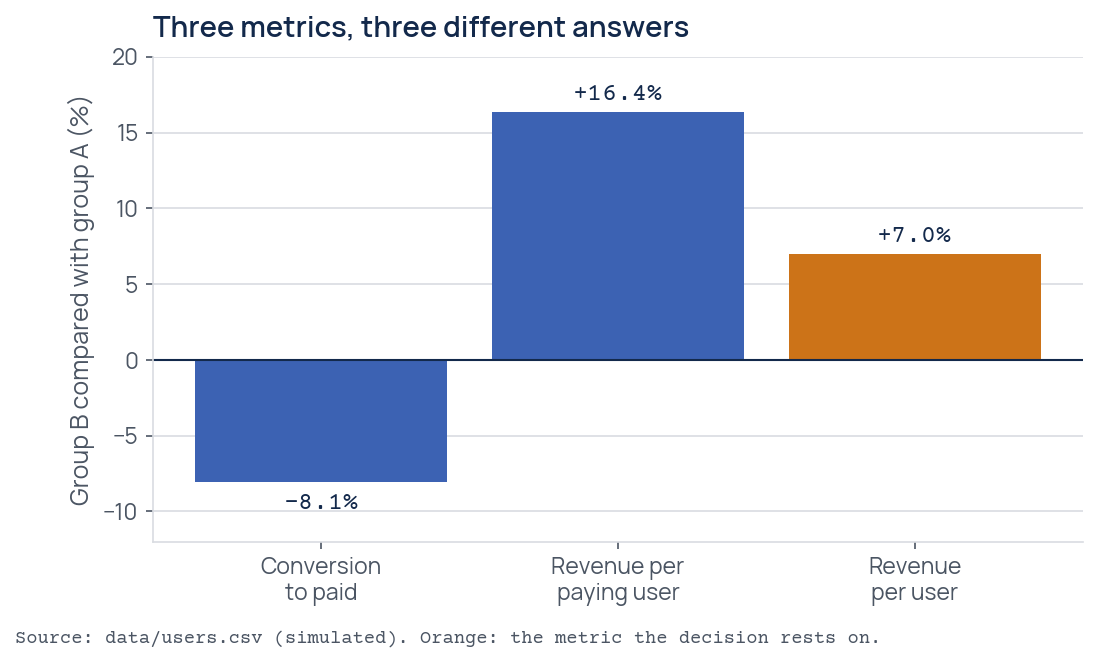

In [21]:
fig, ax = plt.subplots(figsize=(8, 4.2))
names = ["Conversion\nto paid", "Revenue per\npaying user", "Revenue\nper user"]
changes = metrics["Change (%)"].to_numpy()
ax.bar(names, changes, width=0.85, color=[BLUE, BLUE, ORANGE])
for x, v in enumerate(changes):
    ax.text(x, v + (0.8 if v >= 0 else -1.8), f"{v:+.1f}%", ha="center", family="monospace", color=INK)
ax.axhline(0, color=INK, linewidth=1)
ax.set_ylim(-12, 20)
ax.set_ylabel("Group B compared with group A (%)")
ax.set_title("Three metrics, three different answers")
fig.text(0.01, -0.05, "Source: data/users.csv (simulated). Orange: the metric the decision rests on.",
         family="monospace", fontsize=9, color=MUTED)
fig.savefig(FIGURES / "06_wrong_metric.png", dpi=200, bbox_inches="tight")
plt.show()

- **Conversion alone** says the higher price loses: 8% fewer payers. A team that optimises conversion would never raise a price.
- **Revenue per paying user** says the higher price wins by 16%. It flatters every price rise, because the users who walked away are not in the average.
- **Revenue per user** counts everyone who saw the paywall. It is the only one of the three that weighs the lost payers against the higher price, and it gives the modest +7% analysed in part 2.

**The protection.** Choose the decision metric before the test, and make it one that counts every user who saw the paywall (rule 2 of part 1).

### 3.4 Limitations of the traps

- **Demonstrations, not proofs.** Each trap is shown on simulated data under simple assumptions. The sizes of the effects would differ in a real product.
- **Peeking.** The simulation uses equally spaced looks and a test on conversion. It shows the problem but does not implement the remedy (a sequential test).
- **Novelty.** The size and duration of the novelty effect are assumptions. In this dataset the weekly samples are too small to prove the effect: the chart needs the built-in line to be read.
- **Metrics.** Three metrics are compared. Real decisions also weigh costs, refunds and effects beyond 12 months, which are not simulated.

---
## Part 4. Decision

### 4.1 The evidence in one table

| Question | What this test found | Certainty |
|---|---|---|
| Does EUR 6.99 lower conversion? | Yes, from 5.04% to 4.63% (-8.1%) | Significant (p = 0.005) |
| Do payers at EUR 6.99 stay for less time? | Yes, 6.0 months against 7.2 | Observed, not tested on its own |
| Does EUR 6.99 raise 12-month revenue per user? | +7.0%, from EUR 1.82 to EUR 1.95 | Not significant (p = 0.055); interval -0.3% to +14.4% |

### 4.2 Applying the rule fixed in part 1

The rule was: *keep EUR 6.99 if revenue per user is higher and the difference is distinguishable from chance; otherwise keep EUR 4.99, the current price.*

Revenue per user is higher, but the difference is not distinguishable from chance at the 5% level. The rule therefore says: **do not switch on this test.**

The result is close to the threshold, so the next question is what it would take to settle it. The cell below computes how small a revenue gain this test could reliably detect, and how many users a new test would need.

In [22]:
z_total = norm.ppf(1 - ALPHA / 2) + norm.ppf(POWER)
variance_sum = rev_a.var(ddof=1) + rev_b.var(ddof=1)

# Smallest revenue gain this test detects 80% of the time.
detectable = z_total * math.sqrt(variance_sum / N_GROUP) / rev_a.mean()
print(f"Smallest gain this test detects reliably: {detectable:+.1%}")


def users_for_revenue_gain(gain):
    """Users per group needed to detect a relative gain in revenue per user (alpha 5%, power 80%)."""
    return math.ceil(z_total ** 2 * variance_sum / (gain * rev_a.mean()) ** 2)


for label, gain in (("the gain observed here", rev_lift), ("the average gain of the 300 repeats", repeat_lift.mean())):
    print(f"Users per group to detect {label} ({gain:+.1%}): {users_for_revenue_gain(gain):,}")

Smallest gain this test detects reliably: +10.2%
Users per group to detect the gain observed here (+7.0%): 95,793
Users per group to detect the average gain of the 300 repeats (+17.6%): 15,192


This test could reliably detect a revenue gain of about 10% or more. The observed 7% is below that. To confirm a true gain of 7%, a new test would need roughly twice the users.

### 4.3 The decision

> **Keep EUR 4.99 for now, and run a confirmation test before switching to EUR 6.99.**
> The higher price lowers conversion by 8%. It raises 12-month revenue per user by an estimated 7%, but this test cannot tell that gain from chance (95% interval -0.3% to +14.4%).

Three options were on the table:

| Option | For | Against |
|---|---|---|
| Switch to EUR 6.99 now | The best estimate is positive, and 97% of the bootstrap redraws favour B | It breaks the rule fixed in advance. Relaxing a rule after a near miss invites false wins |
| Keep EUR 4.99 and close the question | Follows the rule | Walks away from a likely gain of about 7% in revenue |
| **Keep EUR 4.99 and run a confirmation test** | Follows the rule and tests the open question with enough users | Costs time: another test and another follow-up period |

The confirmation test must be a **new** test, with its sample size fixed in advance on revenue (see the calculation above). Simply extending this one until it turns significant would be the peeking trap of part 3.

### 4.4 What would change the decision

- **A confirmation test whose interval for revenue per user lies above zero:** switch to EUR 6.99.
- **A confirmation test showing no gain, or a loss:** keep EUR 4.99 and close the question.
- **Evidence that payers at EUR 6.99 cancel faster after month 12:** the 12-month window would then flatter the higher price, and the decision should rest on a longer period.
- **A large difference between user segments:** the answer could be a different price for different markets, not one price for all.

### 4.5 What only the simulation knows

In this simulation EUR 6.99 is the better price. Across 300 repeats it earns 17.6% more per user on average, and the test finds a significant gain in all of them. This one dataset is the exception, so the cautious decision above is, with hindsight, a missed opportunity.

The method allows for this. A rule that risks only 5% of false wins must sometimes miss a real one, and a team with a single test cannot know which case it is in. The confirmation test is how that risk is managed.

### 4.6 Limitations of the decision

- **It depends on the rule.** With a 10% significance level, or a one-sided test, the same data would support switching. The rule was fixed before the results, which is what makes the decision defensible, not what makes it right.
- **It ignores costs.** Running a second test has a cost in time and revenue that is not quantified here.
- **It rests on one unusual draw.** See section 2.6.

---
## Part 5. The same method on open data

Parts 1 to 4 use data generated for this notebook. That leaves a fair question: does the method only work on data built to suit it? This part applies the same tools to two public datasets that were made by other people.

| Dataset | Content | Licence | Used here for |
|---|---|---|---|
| "A/B test data", Kaggle (`sergylog/ab-test-data`) | 10,000 rows: user, group, revenue. Described by its author as simulated, with deliberate traps | Community Data License Agreement, Sharing 1.0 | The revenue-per-user comparison |
| "Marketing A/B Testing", Kaggle (`faviovaz/marketing-ab-testing`) | 588,101 users: saw an advertisement or a neutral message, bought or not | CC0, public domain | The conversion comparison |

**Neither dataset is a price test.** They check the method and the data checks. They add no evidence about EUR 4.99 against EUR 6.99, and they play no role in the decision of part 4.

The files are not stored in this repository. `data/open/README.md` says where to download them. If they are missing, the cells below say so and skip.

In [23]:
OPEN = ROOT / "data" / "open"
revenue_file, marketing_file = OPEN / "AB_Test_Results.csv", OPEN / "marketing_AB.csv"
have_open_data = revenue_file.exists() and marketing_file.exists()
print("Open datasets found." if have_open_data else "Open datasets not found: see data/open/README.md. The cells below are skipped.")

Open datasets found.


### 5.1 Revenue per user: check the data before comparing

The first dataset has one row per transaction record, with the user's group and revenue. Section 2.1 checked that each user was in one group and counted once. The same check is run here.

In [24]:
if have_open_data:
    raw = pd.read_csv(revenue_file)
    groups_per_user = raw.groupby("USER_ID")["VARIANT_NAME"].nunique()
    in_both = groups_per_user[groups_per_user > 1].index

    print(f"Rows:                          {len(raw):,}")
    print(f"Different users:               {raw['USER_ID'].nunique():,}")
    print(f"Users who appear in BOTH groups: {len(in_both):,}")
    print(f"Rows with revenue above zero:  {(raw['REVENUE'] > 0).mean():.1%}")
    print(f"Largest single revenue:        {raw['REVENUE'].max():.2f}")

Rows:                          10,000
Different users:               6,324
Users who appear in BOTH groups: 1,541
Rows with revenue above zero:  1.5%
Largest single revenue:        196.01


Two problems appear that the simulated data did not have.

- **About a quarter of the users are in both groups.** Their behaviour cannot be attributed to either version, so they are removed. This is the kind of assignment fault that section 2.1 warns about.
- **Some users have several rows.** Revenue is summed per user, because the unit of the test is the user.

In [25]:
if have_open_data:
    clean = raw[~raw["USER_ID"].isin(in_both)].groupby(["USER_ID", "VARIANT_NAME"], as_index=False)["REVENUE"].sum()
    control = clean.loc[clean["VARIANT_NAME"] == "control", "REVENUE"].to_numpy()
    variant = clean.loc[clean["VARIANT_NAME"] == "variant", "REVENUE"].to_numpy()

    def compare_revenue(a, b, seed):
        """Relative change in revenue per user (b against a): Welch p-value and bootstrap 95% interval."""
        rng = np.random.default_rng(seed)
        boot_a, boot_b = bootstrap_means(a, rng), bootstrap_means(b, rng)
        return {"Users (control / variant)": f"{len(a):,} / {len(b):,}",
                "Paying users": f"{(a > 0).sum()} / {(b > 0).sum()}",
                "Revenue per user": f"{a.mean():.3f} / {b.mean():.3f}",
                "Change": b.mean() / a.mean() - 1,
                "Interval low": np.percentile(boot_b / boot_a - 1, 2.5),
                "Interval high": np.percentile(boot_b / boot_a - 1, 97.5),
                "p-value (Welch)": ttest_ind(b, a, equal_var=False).pvalue}

    top = max(control.max(), variant.max())
    open_revenue = pd.DataFrame({
        "All clean users": compare_revenue(control, variant, 11),
        "Without the single largest payer": compare_revenue(control[control < top], variant[variant < top], 12),
    }).T
    display(open_revenue.style.format({"Change": "{:+.1%}", "Interval low": "{:+.1%}", "Interval high": "{:+.1%}", "p-value (Welch)": "{:.3f}"}))

,Users (control / variant),Paying users,Revenue per user,Change,Interval low,Interval high,p-value (Welch)
All clean users,"2,390 / 2,393",54 / 42,0.197 / 0.075,-61.9%,-84.5%,+5.7%,0.162
Without the single largest payer,"2,389 / 2,393",53 / 42,0.115 / 0.075,-34.8%,-66.1%,+22.3%,0.176


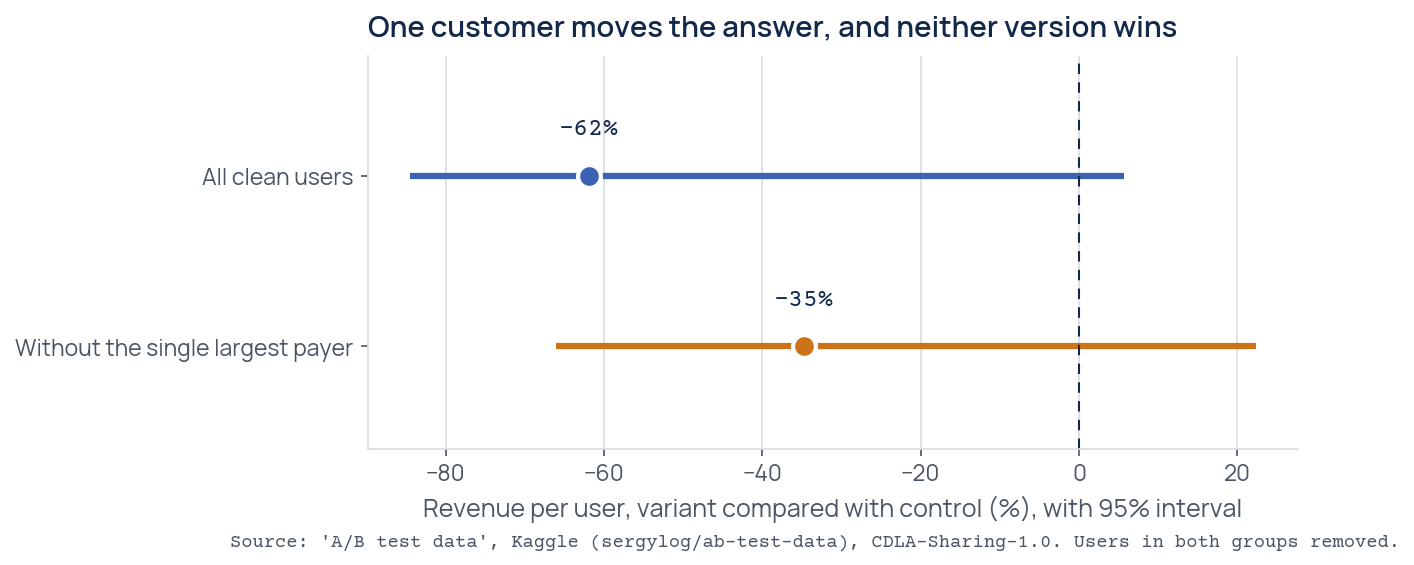

In [26]:
if have_open_data:
    fig, ax = plt.subplots(figsize=(8, 3.4))
    for y, (label, row) in enumerate(open_revenue.iloc[::-1].iterrows()):
        colour = ORANGE if "largest" in label else BLUE
        ax.plot([100 * row["Interval low"], 100 * row["Interval high"]], [y, y], color=colour, linewidth=3, solid_capstyle="butt")
        ax.scatter([100 * row["Change"]], [y], s=120, color=colour, edgecolor="white", linewidth=2, zorder=3)
        ax.text(100 * row["Change"], y + 0.24, f"{row['Change']:+.0%}", ha="center", color=INK, family="monospace")
    ax.axvline(0, color=INK, linewidth=1, linestyle=(0, (5, 4)))
    ax.set_yticks([0, 1], list(open_revenue.index[::-1]))
    ax.set_ylim(-0.6, 1.7)
    ax.grid(axis="y", visible=False)
    ax.grid(axis="x", visible=True)
    ax.set_xlabel("Revenue per user, variant compared with control (%), with 95% interval")
    ax.set_title("One customer moves the answer, and neither version wins")
    fig.text(0.01, -0.08, "Source: 'A/B test data', Kaggle (sergylog/ab-test-data), CDLA-Sharing-1.0. Users in both groups removed.",
             family="monospace", fontsize=9, color=MUTED)
    fig.savefig(FIGURES / "07_open_revenue.png", dpi=200, bbox_inches="tight")
    plt.show()

**Reading the result.** On all clean users the variant looks much worse (-62%), but the interval is wide (-84% to +6%) and the difference is not significant. Almost half of the gap comes from **one** control user with a single very large revenue. Without that user the estimate moves from -62% to -35%, and the interval still includes zero.

This test **cannot tell the two versions apart**. About fifty paying users per group is too few. It is the situation of section 2.4 in a harsher form. Revenue per user is driven by a few payers, so it needs many more users than conversion does, and the distribution has to be looked at before trusting an average.

### 5.2 Conversion: a large test with unequal groups

The second dataset records whether each user bought, after seeing an advertisement or a neutral public-service message. The same two-proportion test as in section 2.3 is used. Here the groups are deliberately unequal.

In [27]:
if have_open_data:
    marketing = pd.read_csv(marketing_file)
    seen_ad = marketing.loc[marketing["test group"] == "ad", "converted"].astype(int)
    seen_psa = marketing.loc[marketing["test group"] == "psa", "converted"].astype(int)

    gap_m, ci_m, p_m = compare_proportions(seen_psa, seen_ad)
    print(f"Users:        {len(seen_psa):,} saw the neutral message, {len(seen_ad):,} saw the advertisement")
    print(f"Share of users in the smaller group: {len(seen_psa) / len(marketing):.1%}")
    print(f"Duplicate users: {int(marketing['user id'].duplicated().sum())}    Missing values: {int(marketing.isna().sum().sum())}")
    print(f"Conversion:   {seen_psa.mean():.2%} (neutral message)   {seen_ad.mean():.2%} (advertisement)")
    print(f"Gap:          {100 * gap_m:+.2f} percentage points  ({seen_ad.mean() / seen_psa.mean() - 1:+.0%} in relative terms)")
    print(f"95% interval: {100 * ci_m[0]:+.2f} to {100 * ci_m[1]:+.2f} percentage points")
    print(f"p-value:      {p_m:.1e}")

    # How small an effect could this test detect? The smaller group sets the limit.
    p0 = seen_psa.mean()
    se0 = math.sqrt(p0 * (1 - p0) * (1 / len(seen_psa) + 1 / len(seen_ad)))
    detectable_m = (norm.ppf(1 - ALPHA / 2) + norm.ppf(POWER)) * se0
    print(f"Smallest gap detectable with 80% power: {100 * detectable_m:.2f} percentage points ({detectable_m / p0:.0%} in relative terms)")

Users:        23,524 saw the neutral message, 564,577 saw the advertisement
Share of users in the smaller group: 4.0%
Duplicate users: 0    Missing values: 0
Conversion:   1.79% (neutral message)   2.55% (advertisement)
Gap:          +0.77 percentage points  (+43% in relative terms)
95% interval: +0.60 to +0.94 percentage points
p-value:      1.7e-13
Smallest gap detectable with 80% power: 0.25 percentage points (14% in relative terms)


**Reading the result.** The data is clean: no user counted twice, nothing missing. The advertisement group converts better, and the interval lies well above zero. With hundreds of thousands of users the interval excludes zero by a wide margin, unlike the small revenue test above.

The split is about 96% to 4%. Unequal groups are legitimate when one version is expected to earn more, but the **smaller group limits the precision**: the test's sensitivity is set by its 23,524 users, not by the half million in the other group.

### 5.3 What the open data adds

| Point made on simulated data | What the open data shows |
|---|---|
| Check that each user is in one group (2.1) | A quarter of the users in the first dataset were in both, so the check matters in practice. |
| Revenue per user is noisy (2.4) | One customer drives the result; about fifty payers per group decide nothing. |
| A well-sized test on conversion separates the groups (2.3) | With 588,101 users the conversion gap is significant (p < 0.001). |
| Sample size sets what a test can see (1.5) | In the unequal test, the small group sets the limit. |

### 5.4 Limitations of this part

- **Neither dataset is a price test.** They support the method, not the decision on EUR 4.99 and EUR 6.99.
- **The first dataset is itself simulated**, according to its author, and was built with traps for teaching. It tests the checks, not reality.
- **Little is known about how either dataset was produced.** The design of the experiments, the dates and the randomisation are not documented, so the results are read as exercises.
- **The second dataset has no revenue.** It says whether a user bought, not how much.
- **The files are not redistributed here.** Their licences allow use; the notebook loads them from a local folder and skips this part if they are absent.

---
## Part 6. A Bayesian reading

Part 2 answered the question *"if the price made no difference, how surprising would this data be?"*. That is the classical (frequentist) view, and it gave p = 0.055 for revenue.

A manager usually asks something else: *"given this data, how likely is it that EUR 6.99 earns more, and what is lost if the choice is wrong?"*. The Bayesian view answers that question directly. It starts from a **prior** (what is believed before the test), updates it with the data, and returns a **posterior**: a full distribution of plausible values for each quantity.

**This part was added after the results of part 2 were known.** It does not replace the decision of part 4. Section 6.5 explains why the two views can disagree, and why the choice between them has to be made before a test.

### 6.1 The model

Revenue per user is the product of three terms (section 2.5). Each uncertain term gets its own simple model.

| Term | Model | Prior |
|---|---|---|
| Conversion to paid | Each user pays or not: Beta-Binomial | Beta(1, 1): every conversion rate equally likely before the test |
| Months paid per payer | Each payer falls in one of 12 classes, 1 to 12 months: Dirichlet-Multinomial | Dirichlet(1, ..., 1): every mix of durations equally likely |
| Price | Known: EUR 4.99 or EUR 6.99 | none |

These priors are deliberately weak, so the data dominates. Both models have exact posteriors, so no approximation is needed. For each group, 200,000 plausible values of each term are drawn and multiplied.

In [28]:
MONTH_VALUES = np.arange(1, 13)
DRAWS = 200_000


def summarise(group):
    """The counts the model needs: users, payers, and payers by number of months paid."""
    return {"n": len(group), "payers": int(group["paid"].sum()),
            "months": np.bincount(group.loc[group["paid"] == 1, "months_paid"], minlength=13)[1:],
            "price": group["price_eur"].iloc[0]}


def posterior(counts, rng, draws=DRAWS, prior=(1, 1)):
    """Posterior draws of conversion, months paid per payer, and revenue per user."""
    conversion = rng.beta(prior[0] + counts["payers"], prior[1] + counts["n"] - counts["payers"], size=draws)
    months = rng.dirichlet(1 + counts["months"], size=draws) @ MONTH_VALUES
    return conversion, months, conversion * counts["price"] * months


counts_a, counts_b = summarise(A), summarise(B)
rng = np.random.default_rng(3)
conv_post_a, months_post_a, rev_post_a = posterior(counts_a, rng)
conv_post_b, months_post_b, rev_post_b = posterior(counts_b, rng)


def describe(label, a, b, better_is_higher):
    change = b / a - 1
    low, high = np.percentile(change, [2.5, 97.5])
    prob = (b > a).mean() if better_is_higher else (b < a).mean()
    direction = "higher" if better_is_higher else "lower"
    print(f"{label:<24} change {np.median(change):+.1%}   95% credible interval {low:+.1%} to {high:+.1%}   P(B {direction}) = {prob:.1%}")


describe("Conversion to paid", conv_post_a, conv_post_b, better_is_higher=False)
describe("Months paid per payer", months_post_a, months_post_b, better_is_higher=False)
describe("Revenue per user", rev_post_a, rev_post_b, better_is_higher=True)

Conversion to paid       change -8.1%   95% credible interval -13.2% to -2.6%   P(B lower) = 99.8%
Months paid per payer    change -16.8%   95% credible interval -19.8% to -13.7%   P(B lower) = 100.0%
Revenue per user         change +7.1%   95% credible interval -0.0% to +14.7%   P(B higher) = 97.5%


### 6.2 Reading the posterior

- **Conversion is lower at EUR 6.99** with a probability above 99%.
- **Payers stay for less time at EUR 6.99**, with a posterior probability that rounds to 100%.
- **Revenue per user is higher at EUR 6.99 with a probability of 97.5%** (97.4% to 97.5% depending on the random draws). The most likely gain is about 7%, and the 95% credible interval runs from about zero to about +15%.

A **credible interval** has the meaning most people wrongly give to a confidence interval: given the model and the data, the true value lies inside it with 95% probability.

The chart shows the whole posterior for the revenue gain. The area to the right of zero is the probability that EUR 6.99 is the better price.

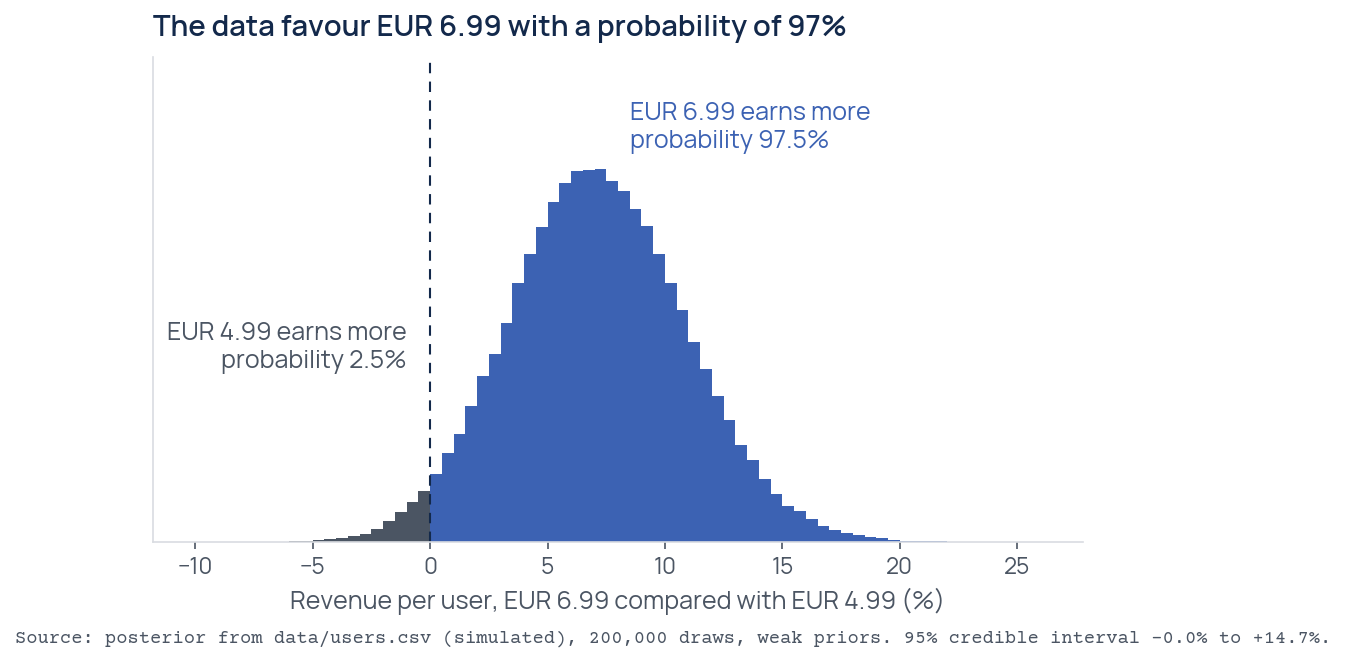

In [29]:
lift_post = rev_post_b / rev_post_a - 1
prob_b_better = (rev_post_b > rev_post_a).mean()
cred_low, cred_high = np.percentile(lift_post, [2.5, 97.5])

fig, ax = plt.subplots(figsize=(8, 4.2))
bins = np.linspace(-0.10, 0.26, 73)
heights, edges = np.histogram(lift_post, bins=bins, density=True)
centres = 100 * (edges[:-1] + edges[1:]) / 2
ax.bar(centres, heights, width=100 * (edges[1] - edges[0]), color=[BLUE if c > 0 else MUTED for c in centres])
ax.axvline(0, color=INK, linewidth=1, linestyle=(0, (5, 4)))
ax.text(8.5, heights.max() * 1.04, f"EUR 6.99 earns more\nprobability {prob_b_better:.1%}", color=BLUE, ha="left", va="bottom")
ax.text(-1.0, heights.max() * 0.45, f"EUR 4.99 earns more\nprobability {1 - prob_b_better:.1%}", color=MUTED, ha="right", va="bottom")
ax.set_ylim(0, heights.max() * 1.3)
ax.set_yticks([])
ax.grid(visible=False)
ax.set_xlabel("Revenue per user, EUR 6.99 compared with EUR 4.99 (%)")
ax.set_title(f"The data favour EUR 6.99 with a probability of {prob_b_better:.0%}")
fig.text(0.01, -0.05, f"Source: posterior from data/users.csv (simulated), {DRAWS:,} draws, weak priors. 95% credible interval {cred_low:+.1%} to {cred_high:+.1%}.",
         family="monospace", fontsize=9, color=MUTED)
fig.savefig(FIGURES / "08_bayes_posterior.png", dpi=200, bbox_inches="tight")
plt.show()

### 6.3 What each choice risks: expected loss

A probability says how likely a choice is to be wrong. It does not say how costly the mistake would be. **Expected loss** combines the two: for each choice, the revenue given up in the cases where it turns out wrong, weighted by how likely those cases are.

In [30]:
loss_if_switch = np.maximum(rev_post_a - rev_post_b, 0).mean()    # the switch is made but 4.99 was better
loss_if_stay = np.maximum(rev_post_b - rev_post_a, 0).mean()      # 4.99 is kept but 6.99 was better

loss_table = pd.DataFrame(
    {"Probability the choice is wrong": [1 - prob_b_better, prob_b_better],
     "Expected loss per user (EUR)": [loss_if_switch, loss_if_stay],
     "Expected loss per 100,000 users (EUR)": [1e5 * loss_if_switch, 1e5 * loss_if_stay]},
    index=["Switch to EUR 6.99", "Keep EUR 4.99"])
display(loss_table.style.format({"Probability the choice is wrong": "{:.1%}", "Expected loss per user (EUR)": "{:.4f}",
                                 "Expected loss per 100,000 users (EUR)": "{:,.0f}"}))
print(f"Keeping EUR 4.99 carries an expected loss about {loss_if_stay / loss_if_switch:,.0f} times larger than switching.")

,Probability the choice is wrong,Expected loss per user (EUR),"Expected loss per 100,000 users (EUR)"
Switch to EUR 6.99,2.5%,0.0006,62
Keep EUR 4.99,97.5%,0.1300,"13,002"


Keeping EUR 4.99 carries an expected loss about 210 times larger than switching.


Switching can only go wrong in the small share of cases where EUR 4.99 is in fact better, and in those cases the gap is small. Keeping EUR 4.99 goes wrong in almost every case, and the gap is then the whole gain. Under this model, on this data, **the Bayesian reading favours switching to EUR 6.99**.

### 6.4 Does the prior matter?

A prior is a choice, so the result has to be checked against other reasonable priors. Three are compared for conversion.

In [31]:
prior_options = {
    "Weak: Beta(1, 1), no prior knowledge": (1, 1),
    "Informed: about 5%, worth 1,000 past users in each group": (50, 950),
    "Strong and equal: about 5%, worth 10,000 past users in each group": (500, 9500),
}
rows = {}
for label, prior in prior_options.items():
    check_rng = np.random.default_rng(4)
    post_a = posterior(counts_a, check_rng, prior=prior)[2]
    post_b = posterior(counts_b, check_rng, prior=prior)[2]
    low, high = np.percentile(post_b / post_a - 1, [2.5, 97.5])
    rows[label] = {"P(EUR 6.99 earns more)": (post_b > post_a).mean(), "Interval low": low, "Interval high": high}
display(pd.DataFrame(rows).T.style.format({"P(EUR 6.99 earns more)": "{:.1%}", "Interval low": "{:+.1%}", "Interval high": "{:+.1%}"}))

,P(EUR 6.99 earns more),Interval low,Interval high
"Weak: Beta(1, 1), no prior knowledge",97.4%,-0.0%,+14.7%
"Informed: about 5%, worth 1,000 past users in each group",97.8%,+0.2%,+14.9%
"Strong and equal: about 5%, worth 10,000 past users in each group",99.5%,+2.1%,+16.0%


With 44,829 users per group, a weak or moderately informed prior barely changes the answer. The third prior does change it. Giving **both** groups the same strong prior on conversion pulls their conversion rates towards each other. In effect it assumes that the price hardly affects conversion, which makes the higher price look better. **A prior always carries an assumption.** The weak prior is used for all the results in this part.

### 6.5 Why the two readings disagree

The classical rule of part 1 says *do not switch*. The Bayesian reading says *switch*. They use the same data, so the evidence cannot be what differs. The next cell compares the two numbers directly.

In [32]:
print(f"Classical, two-sided p-value:           {p_rev:.3f}   (rule: below 0.050)")
print(f"Classical, one-sided p-value:           {p_rev / 2:.3f}")
print(f"1 minus the one-sided p-value:          {1 - p_rev / 2:.1%}")
print(f"Bayesian probability that B earns more: {prob_b_better:.1%}")

Classical, two-sided p-value:           0.055   (rule: below 0.050)
Classical, one-sided p-value:           0.028
1 minus the one-sided p-value:          97.2%
Bayesian probability that B earns more: 97.5%


With weak priors and this much data, the Bayesian probability that B is better is almost the same number as one minus the **one-sided** p-value. The two methods measure the same evidence.

What differs is the **threshold**. The rule of part 1 is two-sided at 5%, which asks for 97.5% in the direction of the gain. A common Bayesian rule asks for 95%. This test gives between 97.2% and 97.5%, depending on the method and on the random draws. It passes the looser bar and sits on the stricter one, a little below it.

The disagreement therefore concerns how much evidence to ask for before changing a price, which depends on what a wrong change costs compared with a missed gain. This is why the threshold must be fixed before the test. Choosing the framework after seeing which one gives the wanted answer would be the same mistake as peeking.

### 6.6 How the rules behave over many tests

A rule should be judged over many tests, not on one. Three rules are compared in two worlds: one where EUR 6.99 really is better (the 300 repeats of section 2.6), and one where the two prices are truly equal, so that any switch is a false alarm.

In [33]:
def classical_switch(counts_1, counts_2):
    """True if group 2 earns significantly more per user (two-sided 5% rule), from the counts alone."""
    def mean_and_variance(c):
        mean = c["price"] * (c["months"] @ MONTH_VALUES) / c["n"]
        return mean, c["price"] ** 2 * (c["months"] @ MONTH_VALUES ** 2) / c["n"] - mean ** 2
    (m1, v1), (m2, v2) = mean_and_variance(counts_1), mean_and_variance(counts_2)
    return (m2 - m1) / math.sqrt(v1 / counts_1["n"] + v2 / counts_2["n"]) > norm.ppf(1 - ALPHA / 2)


def bayes_probability(counts_1, counts_2, rng, draws=4000):
    return (posterior(counts_2, rng, draws)[2] > posterior(counts_1, rng, draws)[2]).mean()


sim_rng = np.random.default_rng(5)

# World 1: EUR 6.99 really is better (same 300 runs as section 2.6).
world_1 = []
for seed in range(300):
    run = simulate.simulate(seed)
    c1, c2 = summarise(run[run["group"] == "A"]), summarise(run[run["group"] == "B"])
    world_1.append((classical_switch(c1, c2), bayes_probability(c1, c2, sim_rng)))

# World 2: both groups get EUR 4.99 and behave alike. 2,000 runs, generated directly from the counts.
churn = simulate.MONTHLY_CHURN["A"]
month_shares = np.array([(1 - churn) ** (k - 1) * churn for k in range(1, 12)] + [(1 - churn) ** 11])
world_2 = []
for _ in range(2000):
    pair = []
    for _ in range(2):
        payers = sim_rng.binomial(N_GROUP, simulate.PAID_RATE["A"])
        pair.append({"n": N_GROUP, "payers": payers, "months": sim_rng.multinomial(payers, month_shares), "price": simulate.PRICE["A"]})
    world_2.append((classical_switch(*pair), bayes_probability(*pair, sim_rng)))


def switch_rates(world):
    classical = np.array([w[0] for w in world])
    prob = np.array([w[1] for w in world])
    return {"Classical, two-sided 5%": classical.mean(), "Bayesian, P at least 95%": (prob >= 0.95).mean(),
            "Bayesian, P at least 97.5%": (prob >= 0.975).mean()}


rules = pd.DataFrame({"EUR 6.99 truly better: share of tests that switch": switch_rates(world_1),
                      "Prices truly equal: share of tests that switch (false alarms)": switch_rates(world_2)})
display(rules.style.format("{:.1%}"))

,EUR 6.99 truly better: share of tests that switch,Prices truly equal: share of tests that switch (false alarms)
"Classical, two-sided 5%",100.0%,3.1%
"Bayesian, P at least 95%",100.0%,5.9%
"Bayesian, P at least 97.5%",100.0%,3.0%


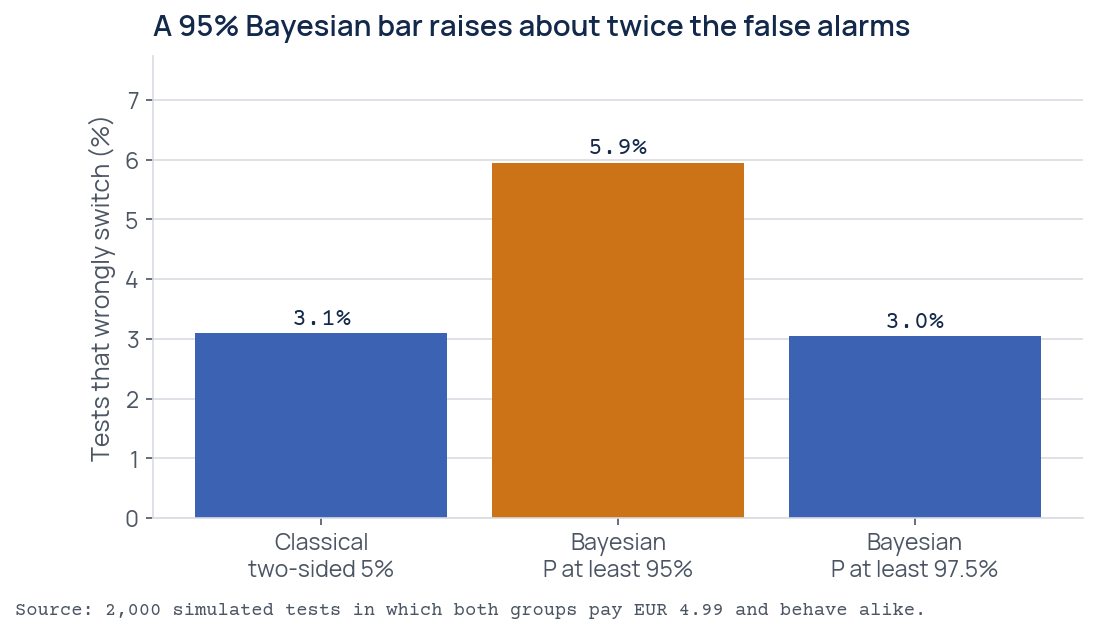

In [34]:
false_alarms_rule = rules.iloc[:, 1]
fig, ax = plt.subplots(figsize=(8, 4.0))
names = ["Classical\ntwo-sided 5%", "Bayesian\nP at least 95%", "Bayesian\nP at least 97.5%"]
values = 100 * false_alarms_rule.to_numpy()
ax.bar(names, values, width=0.85, color=[BLUE, ORANGE, BLUE])
for x, v in enumerate(values):
    ax.text(x, v + 0.15, f"{v:.1f}%", ha="center", family="monospace", color=INK)
ax.set_ylim(0, max(values) * 1.3)
ax.set_ylabel("Tests that wrongly switch (%)")
ax.set_title("A 95% Bayesian bar raises about twice the false alarms")
fig.text(0.01, -0.05, "Source: 2,000 simulated tests in which both groups pay EUR 4.99 and behave alike.",
         family="monospace", fontsize=9, color=MUTED)
fig.savefig(FIGURES / "09_rules_compared.png", dpi=200, bbox_inches="tight")
plt.show()

- **When EUR 6.99 really is better, every rule finds it** in all 300 tests. On a typical dataset the choice of rule would not matter.
- **When the prices are equal, the rules differ.** The 95% Bayesian rule switches wrongly about twice as often as the classical rule. Raise its bar to 97.5% and it behaves like the classical rule.

At 95% the Bayesian rule is a **looser** rule with the same evidence behind it. It catches a real gain sooner and pays for it with more false alarms.

### 6.7 What this part adds

| Question | Answer |
|---|---|
| How likely is it that EUR 6.99 earns more? | 97.5%, on this data and with weak priors. |
| What does each choice risk? | Keeping EUR 4.99 carries an expected loss about 210 times larger than switching. |
| Does this overturn part 4? | No. The rule fixed in advance was two-sided at 5%, which is the same bar as 97.5% here. The test sits right on that bar under either framework, and the classical p-value of 0.055 falls on the wrong side of it. |
| What would be decided differently next time? | The threshold. If a missed gain costs about as much as a wrong switch, a 95% bar, or an expected-loss rule, is the better design. It has to be chosen before the test. |

It also strengthens the case for the confirmation test of part 4: the evidence points one way, and one more properly sized test would settle it.

### 6.8 Limitations of this part

- **Added after the results.** The Bayesian reading was not planned in part 1. It is a second view of a test already analysed, not an independent confirmation.
- **The priors are choices.** Weak priors are used; section 6.4 shows that a strong prior can move the answer.
- **The model is simple.** Conversion and months paid are treated as independent, every payer in a group is assumed alike, and the novelty effect of the first week is ignored.
- **The model matches how the data was generated.** On real data the true process is unknown, and a model that fits this well is not available.
- **The thresholds are conventions.** 95% is no more natural than 5%. An expected-loss rule needs a figure for the loss the business accepts, which is not set here.
- **Simulation error.** Probabilities come from random draws and can move by a few tenths of a percentage point with another seed.

---
## Limitations and disclaimer

This section gathers the limitations noted in each part. Read it before using any number from this notebook.

**About the data**

1. **All data is simulated.** There are no real users, no real app and no real payments. The results describe the assumptions written at the top of `data/simulate.py`, not any market.
2. **The assumptions are placeholders.** Baseline conversion (5.0%), the fall at the higher price (to 4.6%), monthly cancellation rates (10.5% and 13.0%) and the size of the novelty effect were chosen for illustration, not estimated from data.
3. **The simulated users are simpler than real ones.** Users arrive evenly, behave independently, have a constant chance of cancelling each month, and never get refunds, discounts, annual plans or price changes.
4. **The dataset is one unlucky draw.** Its revenue gain (+7.0%) is lower than in all 300 repeat runs of the same simulation (average +17.6%). It was kept on purpose and not replaced.

**About the design**

5. **Sized on conversion, decided on revenue.** The sample size is planned on conversion; the decision metric, revenue, is noisier.
6. **Conventional thresholds.** The 5% significance level and 80% power are conventions.
7. **A 12-month follow-up is long.** A real decision would probably rest on an earlier forecast.

**About the analysis**

8. **A borderline p-value.** The revenue result (p = 0.055) sits just above the threshold fixed in advance.
9. **No segments, one market.** The analysis does not look at differences between groups of users. Prices can differ by country, with each market tested on its own.
10. **Two prices, one plan.** The test compares one monthly price with another. Real paywalls usually offer weekly, monthly and annual plans whose prices affect each other. The test says nothing about other prices or plans, and the best price may be neither.

**About the traps**

11. **Demonstrations under simple assumptions.** The peeking, novelty and metric examples show the direction of each problem, not its size in a real product.
12. **No remedy implemented for peeking.** The notebook shows why early stopping fails but does not implement a sequential test.
13. **The novelty effect is assumed.** Its size and duration are set in the simulation and cannot be proven from this one dataset.

**About the decision**

14. **The decision follows a rule, and other rules exist.** A different significance level or a one-sided test would give a different answer on the same data.
15. **Costs are not counted.** The cost of running a second test, and of waiting, is not quantified.

**About the open data**

16. **The open datasets are not price tests.** Part 5 supports the method and the data checks. It adds no evidence about the two prices.
17. **Their origin is thinly documented.** One is simulated by its author; for both, the design of the experiment is not described.

**About the Bayesian reading**

18. **It was added after the results.** Part 6 is a second view of the same test, not an independent confirmation, and it does not change the decision.
19. **Its priors, model and thresholds are choices.** A strong prior or a different threshold gives a different answer, and the model is simpler than real behaviour.

**Disclaimer.** This notebook is an exercise in method. It is not pricing advice, and its figures must not be quoted as evidence about real products. Showing different prices to different users also raises legal and fairness questions that depend on the country and the app store; they are outside the scope of this exercise.